In [80]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [81]:
def load_field(mat, name, shape):
    """Restore a Lumerical vector field to MATLAB's spatial/component order."""
    raw = mat[f"{name}/{name}"][()].T
    values = raw["real"] + 1j * raw["imag"] if raw.dtype.names else raw.astype(complex)
    return values.reshape(shape, order="F")


def load_ey_origin_cuts(path):
    """Read only Ey on the y/z cuts nearest the origin from a single-x/f export."""
    path = Path(path)
    with h5py.File(path, "r") as mat:
        coords = {key: mat[f"E/{key}"][()].ravel() for key in ("x", "y", "z", "f")}
        x, y, z, frequency = (coords[key] for key in ("x", "y", "z", "f"))
        if x.size != 1 or frequency.size != 1:
            raise ValueError(f"{path}: select one x plane and frequency.")
        if not (np.all(np.diff(y) > 0) and np.all(np.diff(z) > 0)):
            raise ValueError(f"{path}: coordinates must be increasing.")
        iy, iz = int(np.argmin(abs(y))), int(np.argmin(abs(z)))
        dataset = mat["E/E"]
        if dataset.shape != (3, y.size * z.size):
            raise ValueError(f"{path}: unexpected field storage shape {dataset.shape}.")
        raw_y = dataset[1, iz * y.size:(iz + 1) * y.size]
        raw_z = dataset[1, iy: y.size * z.size: y.size]
        ey_y = raw_y["real"] + 1j * raw_y["imag"] if raw_y.dtype.names else raw_y.astype(complex)
        ey_z = raw_z["real"] + 1j * raw_z["imag"] if raw_z.dtype.names else raw_z.astype(complex)
    return {
        "path": path, "x_um": float(x[0] * 1e6), "frequency_hz": float(frequency[0]),
        "y": {"position_um": y * 1e6, "field": ey_y, "origin_index": iy, "fixed_um": float(z[iz] * 1e6)},
        "z": {"position_um": z * 1e6, "field": ey_z, "origin_index": iz, "fixed_um": float(y[iy] * 1e6)},
    }


def load_monitor_23(path):
    with h5py.File(path, "r") as mat:
        coordinates = {key: mat[f"E/{key}"][()].ravel()
                       for key in ("x", "y", "z", "f", "lambda")}
        shape = tuple(coordinates[key].size for key in ("x", "y", "z", "f")) + (3,)
        if shape[0] != 1 or shape[3] != 1:
            raise ValueError(f"{path.name}: select a single x plane and frequency.")
        fields = {}
        for name in ("E", "H"):
            fields[name] = load_field(mat, name, shape)
    result = {**coordinates, **fields, "path": path}
    result["y_um"], result["z_um"] = coordinates["y"] * 1e6, coordinates["z"] * 1e6
    result["iy0"] = int(np.argmin(np.abs(coordinates["y"])))
    result["iz0"] = int(np.argmin(np.abs(coordinates["z"])))
    result["intensity"] = np.sum(np.abs(fields["E"][0, :, :, 0, :])**2, axis=-1)
    result["Ey"] = fields["E"][0, :, :, 0, 1]
    return result


def load_electric_intensity(path):
    """Load total |E|² on a single-x/f plane without retaining full E/H arrays."""
    path = Path(path)
    with h5py.File(path, "r") as mat:
        coords = {key: mat[f"E/{key}"][()].ravel() for key in ("x", "y", "z", "f", "lambda")}
        x, y, z, frequency = (coords[key] for key in ("x", "y", "z", "f"))
        if x.size != 1 or frequency.size != 1:
            raise ValueError(f"{path}: select one x plane and frequency.")
        if not (np.all(np.diff(y) > 0) and np.all(np.diff(z) > 0)):
            raise ValueError(f"{path}: coordinates must be increasing.")
        dataset = mat["E/E"]
        if dataset.shape != (3, y.size * z.size):
            raise ValueError(f"{path}: unexpected field storage shape {dataset.shape}.")
        intensity = np.zeros((y.size, z.size))
        for component in range(3):
            raw = dataset[component, :]
            field = raw["real"] + 1j * raw["imag"] if raw.dtype.names else raw.astype(complex)
            intensity += (abs(field)**2).reshape(intensity.shape, order="F")
    return {**coords, "path": path, "intensity": intensity,
            "y_um": y * 1e6, "z_um": z * 1e6,
            "iy0": int(np.argmin(abs(y))), "iz0": int(np.argmin(abs(z)))}


In [ ]:
def gaussian(position, amplitude, center, sigma, offset):
    return offset + amplitude * np.exp(-0.5 * ((position - center) / sigma)**2)


def fit_gaussian(position, intensity):
    # Normalize for numerical stability; return parameters in original units.
    scale = intensity.max()
    normalized = intensity / scale
    peak = np.argmax(normalized)
    baseline = normalized.min()
    half_height = baseline + (normalized[peak] - baseline) / 2
    left = right = peak
    while left > 0 and normalized[left - 1] >= half_height:
        left -= 1
    while right < position.size - 1 and normalized[right + 1] >= half_height:
        right += 1
    spacing = np.min(np.abs(np.diff(position)))
    sigma0 = max(position[right] - position[left], spacing) / 2.355
    parameters, _ = curve_fit(
        gaussian, position, normalized,
        p0=[1 - baseline, position[peak], sigma0, baseline],
        bounds=([0, position.min(), spacing / 100, 0],
                [np.inf, position.max(), np.inf, np.inf]),
        maxfev=20000,
    )
    parameters[[0, 3]] *= scale
    predicted = gaussian(position, *parameters)
    total = np.sum((intensity - intensity.mean())**2)
    r_squared = 1 - np.sum((intensity - predicted)**2) / total if total > 0 else np.nan
    return {"parameters": parameters, "center_um": parameters[1],
            "sigma_um": parameters[2], "waist_um": 2 * parameters[2],
            "fwhm_um": 2 * np.sqrt(2 * np.log(2)) * parameters[2],
            "r_squared": r_squared}


def cut_phase(field_cut, origin_index):
    # Unwrap along the cut and set the phase at the origin to zero.
    phase = np.unwrap(np.angle(field_cut))
    return phase - phase[origin_index]


def relative_ey_phase(field_cut, origin_index):
    intensity = np.abs(field_cut)**2
    center_intensity = intensity[origin_index]
    if not np.isfinite(center_intensity) or center_intensity <= 0:
        raise ValueError("Ey intensity at the origin must be positive to define the threshold.")
    # Unwrap first, then mask without connecting across hidden samples.
    phase = np.unwrap(np.angle(field_cut))
    phase -= phase[origin_index]
    visible = intensity >= PHASE_INTENSITY_THRESHOLD * center_intensity
    return np.where(visible, phase, np.nan)


def gaussian_23(u, amplitude, center, waist, background):
    return background + amplitude * np.exp(-2 * ((u - center) / waist)**2)


def fit_beam_23(position_um, intensity):
    scale = float(np.max(intensity))
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("A positive intensity maximum is required for a Gaussian fit.")
    normalized = intensity / scale
    peak = int(np.argmax(normalized))
    baseline = max(0.0, float(normalized.min()))
    half = baseline + (1 - baseline) / 2
    left = right = peak
    while left > 0 and normalized[left - 1] >= half:
        left -= 1
    while right < position_um.size - 1 and normalized[right + 1] >= half:
        right += 1
    spacing = np.min(np.abs(np.diff(position_um)))
    width_guess = max(position_um[right] - position_um[left], spacing) / np.sqrt(2 * np.log(2))
    parameters, _ = curve_fit(
        gaussian_23, position_um, normalized,
        p0=[1 - baseline, position_um[peak], width_guess, baseline],
        bounds=([0, position_um.min(), spacing / 100, 0],
                [np.inf, position_um.max(), np.inf, np.inf]), maxfev=20000,
    )
    predicted = gaussian_23(position_um, *parameters)
    total = np.sum((normalized - normalized.mean())**2)
    r_squared = 1 - np.sum((normalized - predicted)**2) / total if total > 0 else np.nan
    parameters[[0, 3]] *= scale
    return {"parameters": parameters, "waist_um": parameters[2],
            "center_um": parameters[1], "r_squared": r_squared}


def phase_cut_23(field_cut, origin_index):
    intensity = np.abs(field_cut)**2
    center_intensity = intensity[origin_index]
    if not np.isfinite(center_intensity) or center_intensity <= 0:
        raise ValueError("Ey intensity at the origin must be positive for the phase threshold.")
    phase = np.unwrap(np.angle(field_cut))
    phase -= phase[origin_index]
    return np.where(intensity >= PHASE_THRESHOLD_23 * center_intensity, phase, np.nan)


def fit_phase_parabola(position_um, phase_rad, fit_range_um=None):
    """Fit phi = a*u² through the origin; report standard centered R² and phi'' = 2a.

    Use finite (above-threshold) samples with equal weight and an optional fit
    interval. Linear and constant terms are fixed to zero.
    """
    position_um, phase_rad = np.asarray(position_um), np.asarray(phase_rad)
    valid = np.isfinite(position_um) & np.isfinite(phase_rad)
    if fit_range_um is not None:
        valid &= (position_um >= fit_range_um[0]) & (position_um <= fit_range_um[1])
    if np.count_nonzero(valid) < 2:
        raise ValueError("A quadratic fit requires at least two finite phase samples.")
    u, phase = position_um[valid], phase_rad[valid]
    scale = np.max(np.abs(u))
    if scale == 0:
        raise ValueError("A quadratic fit requires nonzero positions.")
    basis = (u / scale)**2
    coefficient = np.dot(basis, phase) / np.dot(basis, basis)
    a = coefficient / scale**2
    predicted = coefficient * basis
    total = np.sum((phase - phase.mean())**2)
    r_squared = 1 - np.sum((phase - predicted)**2) / total if total > 0 else np.nan
    return {"parameters": np.array([a, 0.0, 0.0]), "a_rad_per_um2": a,
            "phase_curvature_rad_per_um2": 2 * a, "r_squared": r_squared,
            "valid_mask": valid, "sample_count": int(valid.sum()),
            "fit_range_um": (float(u.min()), float(u.max()))}


def ey_cut_phase_residual(reference_cut, comparison_cut, threshold=1e-3):
    """Signed principal phase difference (comparison minus reference) on their overlap."""
    phases = []
    for cut in (reference_cut, comparison_cut):
        position, field = cut["position_um"], cut["field"]
        if not np.all(np.diff(position) > 0):
            raise ValueError("Phase comparison requires increasing coordinates.")
        intensity = abs(field)**2
        center = intensity[cut["origin_index"]]
        if not np.isfinite(center) or center <= 0:
            raise ValueError("Ey intensity at the phase reference must be positive.")
        phase = cut_phase(field, cut["origin_index"])
        phases.append(np.where(intensity >= threshold * center, phase, np.nan))
    u0, u1 = reference_cut["position_um"], comparison_cut["position_um"]
    shared = (u0 >= u1.min()) & (u0 <= u1.max())
    if np.count_nonzero(shared) < 2:
        raise ValueError("Not enough overlapping samples for the phase residual.")
    position = u0[shared]
    # NaNs propagate across weak-field interpolation brackets; no extrapolation.
    difference = np.interp(position, u1, phases[1]) - phases[0][shared]
    # Phase is defined modulo 2π; discard independent unwrapping branch offsets.
    residual = np.angle(np.exp(1j * difference))
    if not np.any(np.isfinite(residual)):
        raise ValueError("No phase residual samples exceed the threshold in both files.")
    return {"reference_phase_rad": phases[0], "comparison_phase_rad": phases[1],
            "position_um": position, "residual_rad": residual}


In [ ]:
def plot_ey_phase_comparison(paths, threshold=1e-3, y_limits_um=(-100, 100),
                             fit_labels=(), fit_ranges_um=None):
    """Overlay origin-referenced unwrapped Ey phases on y/z cuts, without residuals."""
    cuts = {label: load_ey_origin_cuts(path) for label, path in paths.items()}
    if not cuts:
        raise ValueError("Choose at least one monitor export.")
    missing_fits = set(fit_labels).difference(cuts)
    if missing_fits:
        raise ValueError(f"Unknown cases requested for parabolic fits: {sorted(missing_fits)}")
    fit_ranges_um = {} if fit_ranges_um is None else fit_ranges_um
    frequency = next(iter(cuts.values()))["frequency_hz"]
    if not all(np.isclose(case["frequency_hz"], frequency, rtol=1e-9, atol=0)
               for case in cuts.values()):
        raise ValueError("All phase comparisons must use the same frequency.")
    fig = plt.figure(figsize=(14, 5.7), constrained_layout=True)
    grid = fig.add_gridspec(2, 2, height_ratios=[0.2, 1])
    legend_ax = fig.add_subplot(grid[0, :])
    legend_ax.set_axis_off()
    axes = [fig.add_subplot(grid[1, col]) for col in range(2)]
    phases = {}
    for label, case in cuts.items():
        phases[label] = {}
        for ax, direction in zip(axes, ("y", "z")):
            cut = case[direction]
            intensity = abs(cut["field"])**2
            center_intensity = intensity[cut["origin_index"]]
            if not np.isfinite(center_intensity) or center_intensity <= 0:
                raise ValueError(f"{label}: Ey intensity at the origin must be positive.")
            phase = cut_phase(cut["field"], cut["origin_index"])
            phase = np.where(intensity >= threshold * center_intensity, phase, np.nan)
            phases[label][direction] = {**cut, "phase_rad": phase}
            line, = ax.plot(cut["position_um"], phase, linewidth=1.5, label=label)
            if label in fit_labels and direction == "y":
                fit = fit_phase_parabola(cut["position_um"], phase, fit_ranges_um.get(direction))
                phases[label][direction]["parabola_fit"] = fit
                fitted_phase = np.where(fit["valid_mask"],
                                        np.polyval(fit["parameters"], cut["position_um"]), np.nan)
                ax.plot(cut["position_um"], fitted_phase, "--", color=line.get_color(),
                        linewidth=2, label="_nolegend_")
    for ax, direction, fixed in zip(axes, ("y", "z"), ("z", "y")):
        ax.set(xlabel=f"{direction} (µm)", ylabel="Unwrapped relative Ey phase (rad)",
               title=f"{direction} cut at {fixed} = 0 µm")
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.axhline(0, color="gray", linewidth=0.7)
        ax.grid(alpha=0.25)
        ax.margins(x=0.02)
    if y_limits_um is not None:
        axes[0].set_xlim(*y_limits_um)
    handles, labels = axes[0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", ncol=min(len(cuts), 3),
                     fontsize="small", frameon=False)
    fig.suptitle(f"Ey phase relative to the origin; intensity ≥ {100 * threshold:g}% of center")
    if fit_labels:
        fig.suptitle(f"Ey phase relative to the origin; intensity ≥ {100 * threshold:g}% of center"
                     "\nDashed: y-cut fits phi(y) = a*y² for Micro-optics and 14× lens")
        print("Y-cut fit: phi(y) = a*y², with y in µm; linear and constant terms fixed to zero.")
        print("Phase curvature = d²phi/du² = 2a (rad/µm²); fits use all finite samples in each range.")
        print(f"{'Case':<31} {'Cut':>3} {'a (rad/µm²)':>14} {'2a (rad/µm²)':>15} {'R²':>9} {'Fit range (µm)':>23}")
        for label in fit_labels:
            for direction in ("y",):
                fit = phases[label][direction]["parabola_fit"]
                lower, upper = fit["fit_range_um"]
                print(f"{label:<31} {direction:>3} {fit['a_rad_per_um2']:14.6g} "
                      f"{fit['phase_curvature_rad_per_um2']:15.6g} {fit['r_squared']:9.5f} "
                      f"[{lower:9.3f}, {upper:9.3f}]")
    print(f"Comparison wavelength: {299792458 / frequency * 1e9:.3f} nm")
    for label, case in cuts.items():
        print(f"{label}: x = {case['x_um']:.6f} µm; "
              f"sampled origin y = {case['z']['fixed_um']:.6f} µm, "
              f"z = {case['y']['fixed_um']:.6f} µm")
    plt.show()
    return cuts, phases, fig


def plot_mode_waists(monitor, title="Lens mode"):
    """Plot total |E|² and Gaussian fits of y/z cuts through the sampled origin."""
    intensity = monitor["intensity"]
    y_um, z_um = monitor["y_um"], monitor["z_um"]
    iy, iz = monitor["iy0"], monitor["iz0"]
    cuts = {
        "y": {"position_um": y_um, "intensity": intensity[:, iz], "fixed_um": float(z_um[iz])},
        "z": {"position_um": z_um, "intensity": intensity[iy, :], "fixed_um": float(y_um[iy])},
    }
    fits = {direction: fit_beam_23(cut["position_um"], cut["intensity"])
            for direction, cut in cuts.items()}
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.7), constrained_layout=True)
    image = axes[0].pcolormesh(y_um, z_um, intensity.T, shading="auto", cmap="inferno")
    axes[0].axhline(z_um[iz], color="cyan", linestyle="--", linewidth=0.9)
    axes[0].axvline(y_um[iy], color="cyan", linestyle="--", linewidth=0.9)
    axes[0].set(xlabel="y (µm)", ylabel="z (µm)", title=r"Mode intensity $|E|^2$")
    axes[0].set_aspect("auto")
    fig.colorbar(image, ax=axes[0], label=r"$|E|^2$ (V$^2$/m$^2$)")
    for ax, direction, fixed in zip(axes[1:], ("y", "z"), ("z", "y")):
        cut, fit = cuts[direction], fits[direction]
        position = cut["position_um"]
        dense = np.linspace(position.min(), position.max(), 2000)
        ax.plot(position, cut["intensity"], color="tab:blue", linewidth=1.4, label="Intensity")
        ax.plot(dense, gaussian_23(dense, *fit["parameters"]), "--", color="tab:orange",
                linewidth=1.7, label="Gaussian fit")
        ax.set(xlabel=f"{direction} (µm)", ylabel=r"$|E|^2$ (V$^2$/m$^2$)",
               title=f"{direction} cut at {fixed} = {cut['fixed_um']:.3f} µm\n"
                     + fr"$w_{direction}$ = {fit['waist_um']:.3f} µm; $R^2$ = {fit['r_squared']:.4f}")
        ax.legend(fontsize="small", loc="upper right")
        ax.grid(alpha=0.25)
        ax.margins(x=0.02, y=0.05)
    for ax in axes:
        ax.set_box_aspect(1)
    fig.suptitle(title)
    print(f"x = {monitor['x'][0] * 1e6:.6f} µm; λ = {monitor['lambda'][0] * 1e9:.3f} nm")
    print("Intensity model: B + A exp[-2((u-u0)/w)²]; w is the 1/e² intensity radius.")
    print("Both cuts use the sampled origin. All intensity samples are fitted; no phase threshold applies.")
    print(f"{'Cut':>3} {'w (µm)':>12} {'Center (µm)':>14} {'R²':>10}")
    for direction, fit in fits.items():
        print(f"{direction:>3} {fit['waist_um']:12.5f} {fit['center_um']:14.5f} {fit['r_squared']:10.6f}")
    plt.show()
    return cuts, fits, fig


def plot_ey_phase_with_residuals(paths, threshold=1e-3, y_limits_um=(-100, 100), fit_y=False):
    """Unwrapped Ey overlays above residuals wrapped to [−π, π]; first case is reference."""
    if len(paths) != 2:
        raise ValueError("Choose exactly two exports, with the reference first.")
    cases = {label: load_ey_origin_cuts(path) for label, path in paths.items()}
    reference_label, comparison_label = list(cases)
    reference, comparison = cases[reference_label], cases[comparison_label]
    if not np.isclose(reference["frequency_hz"], comparison["frequency_hz"], rtol=1e-9, atol=0):
        raise ValueError("Both exports must use the same frequency.")
    fig = plt.figure(figsize=(13, 8), constrained_layout=True)
    grid = fig.add_gridspec(3, 2, height_ratios=[0.18, 2, 1], hspace=0.08)
    legend_ax = fig.add_subplot(grid[0, :]); legend_ax.set_axis_off()
    phase_axes = [fig.add_subplot(grid[1, col]) for col in range(2)]
    residual_axes = [fig.add_subplot(grid[2, col], sharex=phase_axes[col]) for col in range(2)]
    results = {}
    for col, (direction, fixed) in enumerate((("y", "z"), ("z", "y"))):
        result = ey_cut_phase_residual(reference[direction], comparison[direction], threshold)
        results[direction] = result
        top, bottom = phase_axes[col], residual_axes[col]
        top.plot(reference[direction]["position_um"], result["reference_phase_rad"],
                 color="tab:blue", linewidth=1.6, label=reference_label)
        top.plot(comparison[direction]["position_um"], result["comparison_phase_rad"],
                 color="tab:orange", linestyle="--", linewidth=1.6, label=comparison_label)
        top.set(title=f"{direction} cut at {fixed} = 0 µm", ylabel="Unwrapped relative Ey phase (rad)")
        top.tick_params(labelbottom=False)
        bottom.plot(result["position_um"], result["residual_rad"], color="tab:purple", linewidth=1.6)
        bottom.set(xlabel=f"{direction} (µm)", ylabel="Wrapped residual (rad)\no5 − o4")
        for ax in (top, bottom):
            ax.axvline(0, color="gray", linestyle=":", linewidth=0.8)
            ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
            ax.grid(alpha=0.25); ax.margins(x=0.02)
        visible = np.isfinite(result["residual_rad"])
        print(f"{direction} residual: {np.count_nonzero(visible)} shared above-threshold samples; "
              f"coordinate span {result['position_um'][visible].min():.3f} to "
              f"{result['position_um'][visible].max():.3f} µm")
    if fit_y:
        # Use identical coordinates and the shared above-threshold support for both fits.
        result = results["y"]
        u = result["position_um"]
        phase4 = np.interp(u, reference["y"]["position_um"], result["reference_phase_rad"])
        phase5 = np.interp(u, comparison["y"]["position_um"], result["comparison_phase_rad"])
        valid = np.isfinite(phase4) & np.isfinite(phase5)
        if y_limits_um is not None:
            valid &= (u >= y_limits_um[0]) & (u <= y_limits_um[1])
        if valid.sum() < 2:
            raise ValueError("Not enough shared samples for the y phase fits.")
        result["quadratic_fits"] = {}
        annotations = [r"$\phi(y)=a y^2$"]
        for label, phase, color, short in (
                (reference_label, phase4, "tab:blue", "o4"),
                (comparison_label, phase5, "tab:orange", "o5")):
            fit = fit_phase_parabola(u[valid], phase[valid])
            result["quadratic_fits"][label] = fit
            prediction = np.where(valid, fit["a_rad_per_um2"] * u**2, np.nan)
            phase_axes[0].plot(u, prediction, color=color, linestyle=":", linewidth=2)
            annotations.append(f"{short}: a = {fit['a_rad_per_um2']:.6g} rad/µm², "
                               f"R² = {fit['r_squared']:.6f}")
            print(f"{label}: a = {fit['a_rad_per_um2']:.9g} rad/µm², "
                  f"R² = {fit['r_squared']:.8f}; "
                  f"fit range {u[valid].min():.3f} to {u[valid].max():.3f} µm")
        a4, a5 = [fit["a_rad_per_um2"] for fit in result["quadratic_fits"].values()]
        result["delta_a_rad_per_um2"] = a5 - a4
        relative = 100 * (a5 - a4) / a4 if a4 != 0 else np.nan
        result["relative_delta_a_percent"] = relative
        annotations.append(f"Δa (o5 − o4) = {a5-a4:.6g} rad/µm² ({relative:+.3f}%)")
        annotations.append("Dotted lines: quadratic fits")
        phase_axes[0].text(0.5, 0.97, "\n".join(annotations), transform=phase_axes[0].transAxes,
                           ha="center", va="top", fontsize=10,
                           bbox=dict(facecolor="white", edgecolor="0.8", alpha=0.95))
        print(f"Δa (o5 − o4) = {a5-a4:.9g} rad/µm²; relative change = {relative:+.6f}%")
    if y_limits_um is not None:
        phase_axes[0].set_xlim(*y_limits_um)
    handles, labels = phase_axes[0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc="center", ncol=2, frameon=False)
    fig.suptitle(f"14× lens · 729 nm, ion0 · Ey phase and residuals (o5 − o4)\n"
                 f"Origin-referenced phase; intensity ≥ {100 * threshold:g}% of each case's center")
    for label, case in cases.items():
        print(f"{label}: x = {case['x_um']:.6f} µm; sampled y = {case['z']['fixed_um']:.6g} µm, "
              f"z = {case['y']['fixed_um']:.6g} µm")
    plt.show()
    return cases, results, fig


In [84]:
data_path = Path("/home/philip_jacobson/Desktop/DATA1.mat")

# MATLAB v7.3 stores arrays in HDF5 with reversed dimension order.
with h5py.File(data_path, "r") as mat:
    x = mat["E/x"][()].ravel()
    y = mat["E/y"][()].ravel()
    z = mat["E/z"][()].ravel()
    f = mat["E/f"][()].ravel()
    wavelength = mat["E/lambda"][()].ravel()

    shape = (x.size, y.size, z.size, f.size, 3)
    E = load_field(mat, "E", shape)
    H = load_field(mat, "H", shape)

# For this single-x, single-frequency monitor, each component is a (y, z) map.
Ex, Ey, Ez = (E[0, :, :, 0, i] for i in range(3))
Hx, Hy, Hz = (H[0, :, :, 0, i] for i in range(3))
print(f"Loaded {data_path.name}: E {E.shape}, H {H.shape}")
print(f"Component maps: {Ex.shape}; wavelength = {wavelength[0] * 1e9:.3f} nm")


Loaded DATA1.mat: E (1, 3377, 195, 1, 3), H (1, 3377, 195, 1, 3)
Component maps: (3377, 195); wavelength = 729.000 nm


In [85]:
# Change these values, then rerun this cell and the plotting cells below.
FONT_FAMILY = "Arial"  # Choose an installed font, e.g. "Arial" or "Times New Roman".
FONT_SIZE = 14  # points

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "savefig.dpi": 600,  # High resolution for exported images.
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "legend.title_fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

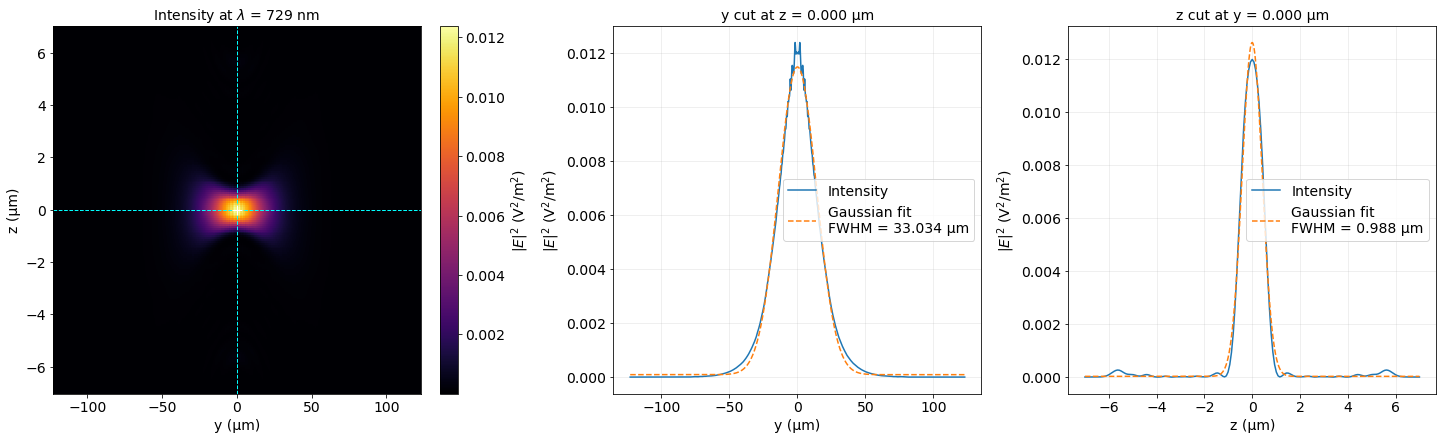

Maximum intensity at y = -1.7488 µm, z = 0.0000 µm
Cuts through y = 0.0000 µm, z = 0.0000 µm
Gaussian model: offset + A exp[-(position-center)²/(2 sigma²)]
y: center = 0.0000 µm, FWHM = 33.0342 µm, 1/e² radius = 28.0567 µm, R² = 0.9964
z: center = -0.0000 µm, FWHM = 0.9883 µm, 1/e² radius = 0.8394 µm, R² = 0.9946


In [86]:
# Electric-field intensity: both cuts pass through the origin.
E2 = np.abs(Ex)**2 + np.abs(Ey)**2 + np.abs(Ez)**2
y_um, z_um = y * 1e6, z * 1e6
iy_max, iz_max = np.unravel_index(np.argmax(E2), E2.shape)
y_peak, z_peak = y_um[iy_max], z_um[iz_max]
# Use the sampled coordinates nearest y = 0 and z = 0.
iy_cut = int(np.argmin(np.abs(y_um)))
iz_cut = int(np.argmin(np.abs(z_um)))
y_fixed_um, z_fixed_um = y_um[iy_cut], z_um[iz_cut]
y_cut = E2[:, iz_cut]
z_cut = E2[iy_cut, :]






y_fit = fit_gaussian(y_um, y_cut)
z_fit = fit_gaussian(z_um, z_cut)

fig, axes = plt.subplots(1, 3, figsize=(20, 6), constrained_layout=True)
ax = axes[0]
image = ax.pcolormesh(y_um, z_um, E2.T, shading="auto", cmap="inferno")
ax.axvline(y_fixed_um, color="cyan", linestyle="--", linewidth=1)
ax.axhline(z_fixed_um, color="cyan", linestyle="--", linewidth=1)
ax.plot(y_fixed_um, z_fixed_um, "+", color="white", markersize=10)
ax.set(xlabel="y (µm)", ylabel="z (µm)",
       title=fr"Intensity at $\lambda$ = {wavelength[0] * 1e9:.0f} nm")
ax.set_aspect("auto")
fig.colorbar(image, ax=ax, label=r"$|E|^2$ (V$^2$/m$^2$)")

for ax, position, intensity, fit, direction, cut_title in [
    (axes[1], y_um, y_cut, y_fit, "y", f"y cut at z = {z_fixed_um:.3f} µm"),
    (axes[2], z_um, z_cut, z_fit, "z", f"z cut at y = {y_fixed_um:.3f} µm"),
]:
    dense = np.linspace(position.min(), position.max(), 2000)
    ax.plot(position, intensity, label="Intensity", linewidth=1.5)
    ax.plot(dense, gaussian(dense, *fit["parameters"]), "--",
            label=f"Gaussian fit\nFWHM = {fit['fwhm_um']:.3f} µm")
    ax.set(xlabel=f"{direction} (µm)", ylabel=r"$|E|^2$ (V$^2$/m$^2$)",
           title=cut_title)
    ax.legend()
    ax.grid(alpha=0.25)

for ax in axes:
    ax.set_box_aspect(1)
plt.show()

print(f"Maximum intensity at y = {y_peak:.4f} µm, z = {z_peak:.4f} µm")
print(f"Cuts through y = {y_fixed_um:.4f} µm, z = {z_fixed_um:.4f} µm")
print("Gaussian model: offset + A exp[-(position-center)²/(2 sigma²)]")
for direction, fit in [("y", y_fit), ("z", z_fit)]:
    print(f"{direction}: center = {fit['center_um']:.4f} µm, "
          f"FWHM = {fit['fwhm_um']:.4f} µm, "
          f"1/e² radius = {fit['waist_um']:.4f} µm, R² = {fit['r_squared']:.4f}")


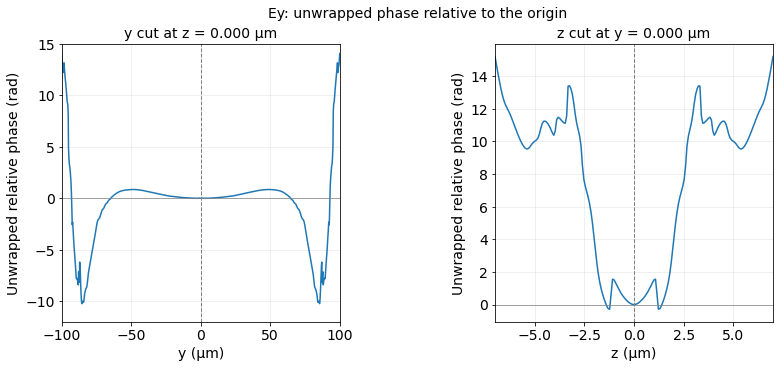

Phase component: Ey


In [87]:
# Phase of one complex E component along the same cuts as the intensity plots.
# Set PHASE_COMPONENT to "Ex", "Ey", or "Ez" to override automatic selection.
PHASE_COMPONENT = "auto"

components = {"Ex": Ex, "Ey": Ey, "Ez": Ez}
phase_component = (max(components, key=lambda name: abs(components[name][iy_cut, iz_cut])**2)
                   if PHASE_COMPONENT == "auto" else PHASE_COMPONENT)
phase_field = components[phase_component]




y_phase = cut_phase(phase_field[:, iz_cut], iy_cut)
z_phase = cut_phase(phase_field[iy_cut, :], iz_cut)

fig_phase, phase_axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, position, phase, direction, reference_position, title in [
    (phase_axes[0], y_um, y_phase, "y", y_fixed_um, f"y cut at z = {z_fixed_um:.3f} µm"),
    (phase_axes[1], z_um, z_phase, "z", z_fixed_um, f"z cut at y = {y_fixed_um:.3f} µm"),
]:
    ax.plot(position, phase, linewidth=1.5)
    ax.axvline(reference_position, color="gray", linestyle="--", linewidth=1)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.set(xlabel=f"{direction} (µm)", ylabel="Unwrapped relative phase (rad)", title=title,
           xlim=(position.min(), position.max()))
    ax.set_box_aspect(1)
    ax.grid(alpha=0.25)

phase_axes[0].set_xlim(-100, 100)
phase_axes[0].set_ylim(-12, 15)


fig_phase.suptitle(f"{phase_component}: unwrapped phase relative to the origin")
plt.show()
print(f"Phase component: {phase_component}")


y cut: sampled z = 0.0000 µm (DATA1), 0.0000 µm (DATA2); residual range [-97.934, 97.934] µm; visible residual samples: 2067/2689
z cut: sampled y = 0.0000 µm (DATA1), 0.0000 µm (DATA2); residual range [-5.990, 5.990] µm; visible residual samples: 63/167


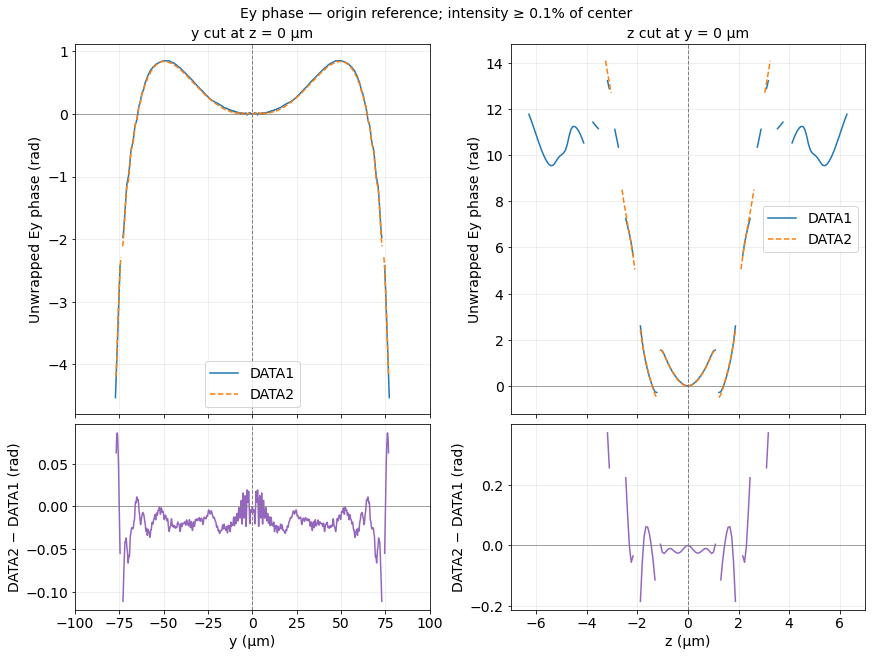

Wavelength: 729.000 nm; monitor x: DATA1 = 238.995064 µm, DATA2 = 238.979431 µm


In [88]:
# Compare DATA1 and DATA2 Ey phase along cuts through (y, z) = (0, 0).
# Run the DATA1 import cell first.
# Hide Ey phase below 0.1% of each dataset's Ey intensity at (0, 0).
PHASE_INTENSITY_THRESHOLD = 1e-3
data2_path = Path("/home/philip_jacobson/Desktop/DATA2.mat")
with h5py.File(data2_path, "r") as mat2:
    x2 = mat2["E/x"][()].ravel()
    y2_um = mat2["E/y"][()].ravel() * 1e6
    z2_um = mat2["E/z"][()].ravel() * 1e6
    f2 = mat2["E/f"][()].ravel()
    if x2.size != 1 or f2.size != 1:
        raise ValueError("Select a single x plane and frequency for DATA2 before comparing.")
    if not np.isclose(f2[0], f[0], rtol=1e-9, atol=0):
        raise ValueError("DATA1 and DATA2 must use the same frequency.")
    raw2 = mat2["E/E"][()].T
    values2 = raw2["real"] + 1j * raw2["imag"]
    Ey2 = values2.reshape((x2.size, y2_um.size, z2_um.size, f2.size, 3),
                          order="F")[0, :, :, 0, 1]

y1_um, z1_um = y * 1e6, z * 1e6
iy1_zero, iz1_zero = int(np.argmin(np.abs(y1_um))), int(np.argmin(np.abs(z1_um)))
iy2_zero, iz2_zero = int(np.argmin(np.abs(y2_um))), int(np.argmin(np.abs(z2_um)))




y1_ey_phase = relative_ey_phase(Ey[:, iz1_zero], iy1_zero)
z1_ey_phase = relative_ey_phase(Ey[iy1_zero, :], iz1_zero)
y2_ey_phase = relative_ey_phase(Ey2[:, iz2_zero], iy2_zero)
z2_ey_phase = relative_ey_phase(Ey2[iy2_zero, :], iz2_zero)

fig_compare, compare_axes = plt.subplots(
    2, 2, figsize=(12, 9), sharex="col", constrained_layout=True,
    gridspec_kw={"height_ratios": [2, 1]},
)
phase_residuals = {}
for col, direction, position1, phase1, position2, phase2, fixed1, fixed2 in [
    (0, "y", y1_um, y1_ey_phase, y2_um, y2_ey_phase, z1_um[iz1_zero], z2_um[iz2_zero]),
    (1, "z", z1_um, z1_ey_phase, z2_um, z2_ey_phase, y1_um[iy1_zero], y2_um[iy2_zero]),
]:
    if not (np.all(np.diff(position1) > 0) and np.all(np.diff(position2) > 0)):
        raise ValueError("Phase comparison requires increasing coordinate arrays.")
    # Interpolate onto DATA1's samples only within the shared domain; no extrapolation.
    common = ((position1 >= max(position1.min(), position2.min())) &
              (position1 <= min(position1.max(), position2.max())))
    if not np.any(common):
        raise ValueError(f"No overlapping {direction} coordinates in the two files.")
    residual_position = position1[common]
    # NaNs in either phase hide the residual. Interpolation also stays hidden
    # when either DATA2 bracketing sample is below threshold.
    residual = np.interp(residual_position, position2, phase2) - phase1[common]
    phase_residuals[direction] = {"position_um": residual_position, "residual_rad": residual}

    top, bottom = compare_axes[:, col]
    fixed_direction = "z" if direction == "y" else "y"
    top.plot(position1, phase1, label="DATA1", linewidth=1.5)
    top.plot(position2, phase2, "--", label="DATA2", linewidth=1.5)
    top.set(title=f"{direction} cut at {fixed_direction} = 0 µm",
            ylabel="Unwrapped Ey phase (rad)")
    top.legend()
    bottom.plot(residual_position, residual, color="tab:purple", linewidth=1.5)
    bottom.set(xlabel=f"{direction} (µm)", ylabel="DATA2 − DATA1 (rad)")
    for ax in [top, bottom]:
        ax.axvline(0, color="gray", linestyle="--", linewidth=1)
        ax.axhline(0, color="gray", linewidth=0.7)
        ax.grid(alpha=0.25)
    print(f"{direction} cut: sampled {fixed_direction} = {fixed1:.4f} µm (DATA1), "
          f"{fixed2:.4f} µm (DATA2); residual range "
          f"[{residual_position.min():.3f}, {residual_position.max():.3f}] µm; "
          f"visible residual samples: {np.count_nonzero(np.isfinite(residual))}/{residual.size}")

compare_axes[0, 0].set_xlim(-100, 100)
compare_axes[0, 1].set_xlim(min(z1_um.min(), z2_um.min()), max(z1_um.max(), z2_um.max()))
fig_compare.suptitle(
    f"Ey phase — origin reference; intensity ≥ {100 * PHASE_INTENSITY_THRESHOLD:g}% of center"
)
plt.show()
print(f"Wavelength: {wavelength[0] * 1e9:.3f} nm; monitor x: "
      f"DATA1 = {x[0] * 1e6:.6f} µm, DATA2 = {x2[0] * 1e6:.6f} µm")


In [89]:
# Independent DATA2/DATA3 comparison; existing DATA1/DATA2 results are preserved.

PHASE_THRESHOLD_23 = 1e-3  # 0.1% of each dataset's Ey intensity at the origin.




datasets_23 = {
    name: load_monitor_23(Path(f"/home/philip_jacobson/Desktop/{name}.mat"))
    for name in ("DATA2", "DATA3")
}
if not np.isclose(datasets_23["DATA2"]["f"][0], datasets_23["DATA3"]["f"][0],
                  rtol=1e-9, atol=0):
    raise ValueError("DATA2 and DATA3 must use the same frequency.")

for name, monitor in datasets_23.items():
    print(f"{name}: E {monitor['E'].shape}, H {monitor['H'].shape}; "
          f"x = {monitor['x'][0] * 1e6:.6f} µm, λ = {monitor['lambda'][0] * 1e9:.3f} nm")
    print(f"  Sampled origin: y = {monitor['y_um'][monitor['iy0']]:.6f} µm, "
          f"z = {monitor['z_um'][monitor['iz0']]:.6f} µm")


DATA2: E (1, 2691, 167, 1, 3), H (1, 2691, 167, 1, 3); x = 238.979431 µm, λ = 729.000 nm
  Sampled origin: y = 0.000000 µm, z = 0.000000 µm
DATA3: E (1, 2635, 265, 1, 3), H (1, 2635, 265, 1, 3); x = 0.994307 µm, λ = 729.000 nm
  Sampled origin: y = 0.000000 µm, z = -0.000000 µm


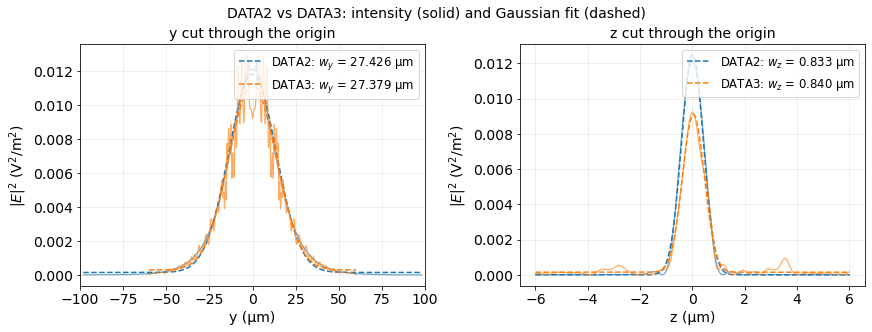

Gaussian w is the 1/e² intensity radius, not the diameter; all intensity samples are fitted.
Dataset         x (µm)    w_y (µm)    w_z (µm)      R²_y      R²_z
DATA2       238.979431     27.4259      0.8327    0.9965    0.9975
DATA3         0.994307     27.3785      0.8399    0.9605    0.9885
Δw_y (DATA3 − DATA2) = -0.0474 µm
Δw_z (DATA3 − DATA2) = +0.0072 µm


In [90]:
# Compare total electric-field intensity and Gaussian 1/e² radii on origin cuts.




waist_results_23 = {}
fig_waists_23, waist_axes_23 = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for (name, monitor), color in zip(datasets_23.items(), ["tab:blue", "tab:orange"]):
    waist_results_23[name] = {}
    for ax, direction, position_um, cut in [
        (waist_axes_23[0], "y", monitor["y_um"], monitor["intensity"][:, monitor["iz0"]]),
        (waist_axes_23[1], "z", monitor["z_um"], monitor["intensity"][monitor["iy0"], :]),
    ]:
        fit = fit_beam_23(position_um, cut)
        waist_results_23[name][direction] = fit
        ax.plot(position_um, cut, color=color, linewidth=1.2, alpha=0.65)
        dense = np.linspace(position_um.min(), position_um.max(), 2000)
        ax.plot(dense, gaussian_23(dense, *fit["parameters"]), "--", color=color,
                label=f"{name}: $w_{direction}$ = {fit['waist_um']:.3f} µm")
        ax.set(xlabel=f"{direction} (µm)", ylabel=r"$|E|^2$ (V$^2$/m$^2$)",
               title=f"{direction} cut through the origin")
        ax.grid(alpha=0.25)
        ax.legend(fontsize="small", loc="upper right")
waist_axes_23[0].set_xlim(-100, 100)
fig_waists_23.suptitle("DATA2 vs DATA3: intensity (solid) and Gaussian fit (dashed)")
plt.show()

print("Gaussian w is the 1/e² intensity radius, not the diameter; all intensity samples are fitted.")
print(f"{'Dataset':<10} {'x (µm)':>11} {'w_y (µm)':>11} {'w_z (µm)':>11} {'R²_y':>9} {'R²_z':>9}")
for name, monitor in datasets_23.items():
    fy, fz = waist_results_23[name]["y"], waist_results_23[name]["z"]
    print(f"{name:<10} {monitor['x'][0] * 1e6:11.6f} {fy['waist_um']:11.4f} "
          f"{fz['waist_um']:11.4f} {fy['r_squared']:9.4f} {fz['r_squared']:9.4f}")
for direction in ("y", "z"):
    change = waist_results_23["DATA3"][direction]["waist_um"] - waist_results_23["DATA2"][direction]["waist_um"]
    print(f"Δw_{direction} (DATA3 − DATA2) = {change:+.4f} µm")


y: 1647/1647 residual samples above the intensity threshold in both files.
z: 70/166 residual samples above the intensity threshold in both files.


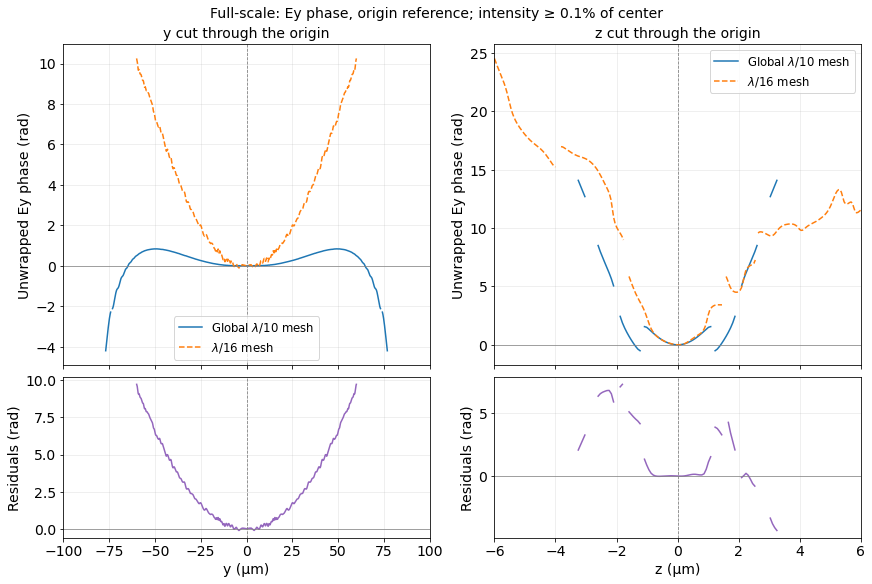

In [91]:
# Unwrapped Ey phase, each referenced to its own origin; residual = DATA3 − DATA2.


phase_cuts_23 = {}
for name, monitor in datasets_23.items():
    phase_cuts_23[name] = {
        "y": (monitor["y_um"], phase_cut_23(monitor["Ey"][:, monitor["iz0"]], monitor["iy0"])),
        "z": (monitor["z_um"], phase_cut_23(monitor["Ey"][monitor["iy0"], :], monitor["iz0"])),
    }

fig_phases_23, phase_axes_23 = plt.subplots(
    2, 2, figsize=(12, 8), sharex="col", constrained_layout=True,
    gridspec_kw={"height_ratios": [2, 1]},
)
phase_residuals_23 = {}
for col, direction in enumerate(("y", "z")):
    position2, phase2 = phase_cuts_23["DATA2"][direction]
    position3, phase3 = phase_cuts_23["DATA3"][direction]
    if not (np.all(np.diff(position2) > 0) and np.all(np.diff(position3) > 0)):
        raise ValueError("Phase interpolation requires increasing coordinate arrays.")
    common = ((position2 >= max(position2.min(), position3.min())) &
              (position2 <= min(position2.max(), position3.max())))
    if not np.any(common):
        raise ValueError(f"No common {direction} range in DATA2 and DATA3.")
    position = position2[common]
    # Interpolate masked phase only over the common domain. NaNs preserve gaps
    # wherever either field or a DATA3 interpolation bracket is below threshold.
    residual = np.interp(position, position3, phase3) - phase2[common]
    phase_residuals_23[direction] = {"position_um": position, "residual_rad": residual}
    top, bottom = phase_axes_23[:, col]
    top.plot(position2, phase2, label="Global $\lambda$/10 mesh", color="tab:blue")
    top.plot(position3, phase3, "--", label="$\lambda$/16 mesh", color="tab:orange")
    top.set(title=f"{direction} cut through the origin", ylabel="Unwrapped Ey phase (rad)")
    top.legend(fontsize="small")
    bottom.plot(position, residual, color="tab:purple")
    bottom.set(xlabel=f"{direction} (µm)", ylabel="Residuals (rad)")
    for ax in (top, bottom):
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.axhline(0, color="gray", linewidth=0.7)
        ax.grid(alpha=0.25)
    print(f"{direction}: {np.count_nonzero(np.isfinite(residual))}/{residual.size} residual samples "
          f"above the intensity threshold in both files.")
phase_axes_23[0, 0].set_xlim(-100, 100)
phase_axes_23[0, 1].set_xlim(
    min(datasets_23[name]["z_um"].min() for name in datasets_23),
    max(datasets_23[name]["z_um"].max() for name in datasets_23),
)
fig_phases_23.suptitle(
    f"Full-scale: Ey phase, origin reference; intensity ≥ {100 * PHASE_THRESHOLD_23:g}% of center"
)
plt.show()


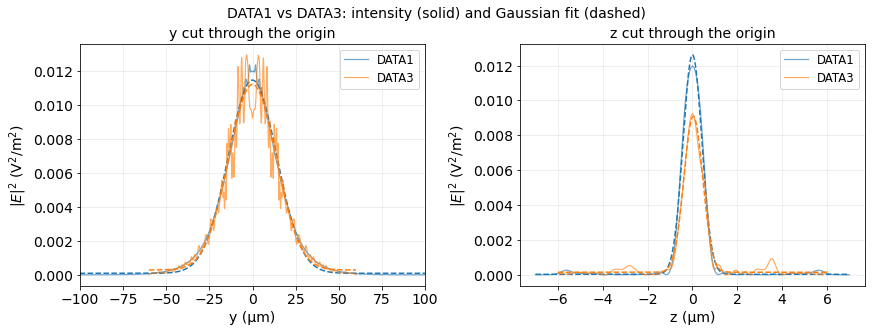

Gaussian w is the 1/e² intensity radius; all intensity samples are fitted.
Dataset         x (µm)    w_y (µm)    w_z (µm)      R²_y      R²_z
DATA1       238.995064     28.0567      0.8394    0.9964    0.9946
DATA3         0.994307     27.3785      0.8399    0.9605    0.9885
Δw_y (DATA3 − DATA1) = -0.6782 µm
Δw_z (DATA3 − DATA1) = +0.0005 µm
y: 1647/1647 residual samples above the intensity threshold in both files.
z: 129/167 residual samples above the intensity threshold in both files.


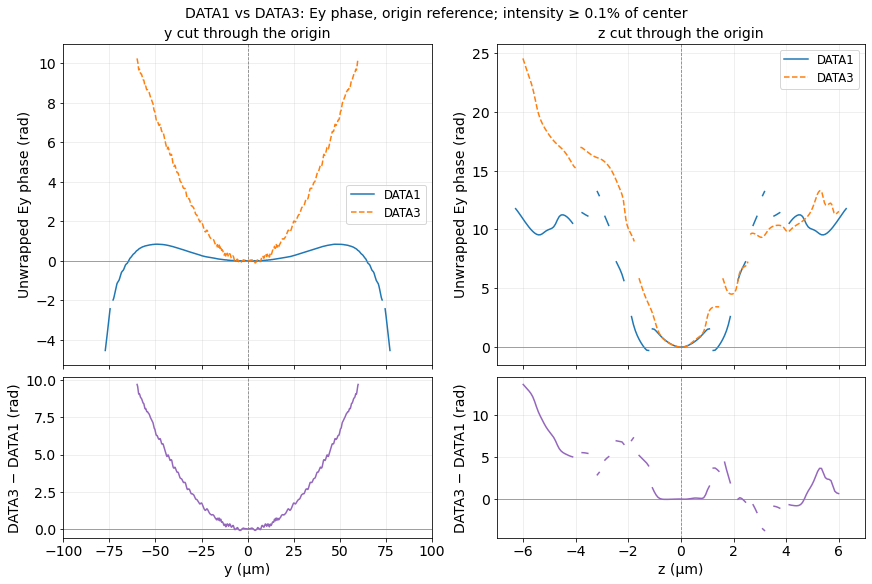

In [92]:
# DATA1/DATA3 comparison using the loader, Gaussian fit, and phase helpers above.
# The DATA2/DATA3 threshold setting PHASE_THRESHOLD_23 also applies here.
datasets_13 = {
    name: load_monitor_23(Path(f"/home/philip_jacobson/Desktop/{name}.mat"))
    for name in ("DATA1", "DATA3")
}
if not np.isclose(datasets_13["DATA1"]["f"][0], datasets_13["DATA3"]["f"][0],
                  rtol=1e-9, atol=0):
    raise ValueError("DATA1 and DATA3 must use the same frequency.")

# Total electric-field intensity and Gaussian 1/e² radii on the origin cuts.
waist_results_13 = {}
fig_waists_13, waist_axes_13 = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for (name, monitor), color in zip(datasets_13.items(), ["tab:blue", "tab:orange"]):
    waist_results_13[name] = {}
    for ax, direction, position_um, cut in [
        (waist_axes_13[0], "y", monitor["y_um"], monitor["intensity"][:, monitor["iz0"]]),
        (waist_axes_13[1], "z", monitor["z_um"], monitor["intensity"][monitor["iy0"], :]),
    ]:
        fit = fit_beam_23(position_um, cut)
        waist_results_13[name][direction] = fit
        ax.plot(position_um, cut, color=color, linewidth=1.2, alpha=0.65, label=name)
        dense = np.linspace(position_um.min(), position_um.max(), 2000)
        ax.plot(dense, gaussian_23(dense, *fit["parameters"]), "--", color=color)
        ax.set(xlabel=f"{direction} (µm)", ylabel=r"$|E|^2$ (V$^2$/m$^2$)",
               title=f"{direction} cut through the origin")
        ax.grid(alpha=0.25)
        ax.legend(fontsize="small", loc="upper right")
waist_axes_13[0].set_xlim(-100, 100)
fig_waists_13.suptitle("DATA1 vs DATA3: intensity (solid) and Gaussian fit (dashed)")
plt.show()

print("Gaussian w is the 1/e² intensity radius; all intensity samples are fitted.")
print(f"{'Dataset':<10} {'x (µm)':>11} {'w_y (µm)':>11} {'w_z (µm)':>11} {'R²_y':>9} {'R²_z':>9}")
for name, monitor in datasets_13.items():
    fy, fz = waist_results_13[name]["y"], waist_results_13[name]["z"]
    print(f"{name:<10} {monitor['x'][0] * 1e6:11.6f} {fy['waist_um']:11.4f} "
          f"{fz['waist_um']:11.4f} {fy['r_squared']:9.4f} {fz['r_squared']:9.4f}")
for direction in ("y", "z"):
    change = waist_results_13["DATA3"][direction]["waist_um"] - waist_results_13["DATA1"][direction]["waist_um"]
    print(f"Δw_{direction} (DATA3 − DATA1) = {change:+.4f} µm")

# Unwrapped Ey phase referenced to each origin, with the same intensity threshold.
phase_cuts_13 = {}
for name, monitor in datasets_13.items():
    phase_cuts_13[name] = {
        "y": (monitor["y_um"], phase_cut_23(monitor["Ey"][:, monitor["iz0"]], monitor["iy0"])),
        "z": (monitor["z_um"], phase_cut_23(monitor["Ey"][monitor["iy0"], :], monitor["iz0"])),
    }

fig_phases_13, phase_axes_13 = plt.subplots(
    2, 2, figsize=(12, 8), sharex="col", constrained_layout=True,
    gridspec_kw={"height_ratios": [2, 1]},
)
phase_residuals_13 = {}
for col, direction in enumerate(("y", "z")):
    position1, phase1 = phase_cuts_13["DATA1"][direction]
    position3, phase3 = phase_cuts_13["DATA3"][direction]
    if not (np.all(np.diff(position1) > 0) and np.all(np.diff(position3) > 0)):
        raise ValueError("Phase interpolation requires increasing coordinate arrays.")
    common = ((position1 >= max(position1.min(), position3.min())) &
              (position1 <= min(position1.max(), position3.max())))
    if not np.any(common):
        raise ValueError(f"No common {direction} range in DATA1 and DATA3.")
    position = position1[common]
    # No extrapolation or interpolation across below-threshold gaps.
    residual = np.interp(position, position3, phase3) - phase1[common]
    phase_residuals_13[direction] = {"position_um": position, "residual_rad": residual}
    top, bottom = phase_axes_13[:, col]
    top.plot(position1, phase1, label="DATA1", color="tab:blue")
    top.plot(position3, phase3, "--", label="DATA3", color="tab:orange")
    top.set(title=f"{direction} cut through the origin", ylabel="Unwrapped Ey phase (rad)")
    top.legend(fontsize="small")
    bottom.plot(position, residual, color="tab:purple")
    bottom.set(xlabel=f"{direction} (µm)", ylabel="DATA3 − DATA1 (rad)")
    for ax in (top, bottom):
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.axhline(0, color="gray", linewidth=0.7)
        ax.grid(alpha=0.25)
    print(f"{direction}: {np.count_nonzero(np.isfinite(residual))}/{residual.size} residual samples "
          f"above the intensity threshold in both files.")
phase_axes_13[0, 0].set_xlim(-100, 100)
phase_axes_13[0, 1].set_xlim(
    min(datasets_13[name]["z_um"].min() for name in datasets_13),
    max(datasets_13[name]["z_um"].max() for name in datasets_13),
)
fig_phases_13.suptitle(
    f"DATA1 vs DATA3: Ey phase, origin reference; intensity ≥ {100 * PHASE_THRESHOLD_23:g}% of center"
)
plt.show()


In [ ]:
# Ey-only lens comparison: DATA1, DATA3, and the new 14× lens export.
PHASE_THRESHOLD_14X = 1e-3  # Hide intensity below 0.1% of each case's central |Ey|².
phase_paths_14x = {
    "Global λ/10": Path("/home/philip_jacobson/Desktop/DATA1.mat"),
    "Micro-optics λ/16": Path("/home/philip_jacobson/Desktop/DATA3.mat"),
    "14× lens (auto xy 4, z 12 nm)": Path(
        "/home/philip_jacobson/Desktop/Planar_lens_scale_14X/729nm_ion0/xy_lambda_o4_z_12nm/lens.mat"
    ),
}
# Orange and green: fit only y phase with phi(y) = a*y²; z is displayed without fitting.
PARABOLA_CASES_14X = ("Micro-optics λ/16", "14× lens (auto xy 4, z 12 nm)")
PARABOLA_FIT_RANGES_14X = {"y": None}  # None: all visible samples; or (min, max) µm.
ey_cuts_14x, ey_phases_14x, fig_ey_phase_14x = plot_ey_phase_comparison(
    phase_paths_14x, threshold=PHASE_THRESHOLD_14X, y_limits_um=(-100, 100),
    fit_labels=PARABOLA_CASES_14X, fit_ranges_um=PARABOLA_FIT_RANGES_14X,
)
parabola_results_14x = {
    label: {direction: ey_phases_14x[label][direction]["parabola_fit"] for direction in ("y",)}
    for label in PARABOLA_CASES_14X
}


In [ ]:
# Auto xy accuracy 4, z step 12 nm: total electric-field intensity and beam radii.
mode_path_14x = Path(
    "/home/philip_jacobson/Desktop/Planar_lens_scale_14X/729nm_ion0/xy_lambda_o4_z_12nm/lens.mat"
)
mode_14x = load_electric_intensity(mode_path_14x)
mode_cuts_14x, mode_waists_14x, fig_mode_waists_14x = plot_mode_waists(
    mode_14x, title="14× lens: automatic xy accuracy 4, z mesh step 12 nm",
)


y residual: 5485 shared above-threshold samples; coordinate span -67.704 to 67.704 µm
z residual: 303 shared above-threshold samples; coordinate span -2.924 to 2.924 µm
Auto xy accuracy 4, z 12 nm: a = 0.00453333865 rad/µm², R² = 0.99800059; fit range -67.704 to 67.704 µm
Auto xy accuracy 5, z 12 nm: a = 0.00469998044 rad/µm², R² = 0.99798193; fit range -67.704 to 67.704 µm
Δa (o5 − o4) = 0.000166641789 rad/µm²; relative change = +3.675918%
Auto xy accuracy 4, z 12 nm: x = 238.992190 µm; sampled y = 0 µm, z = 0 µm
Auto xy accuracy 5, z 12 nm: x = 239.010101 µm; sampled y = 0 µm, z = 0 µm


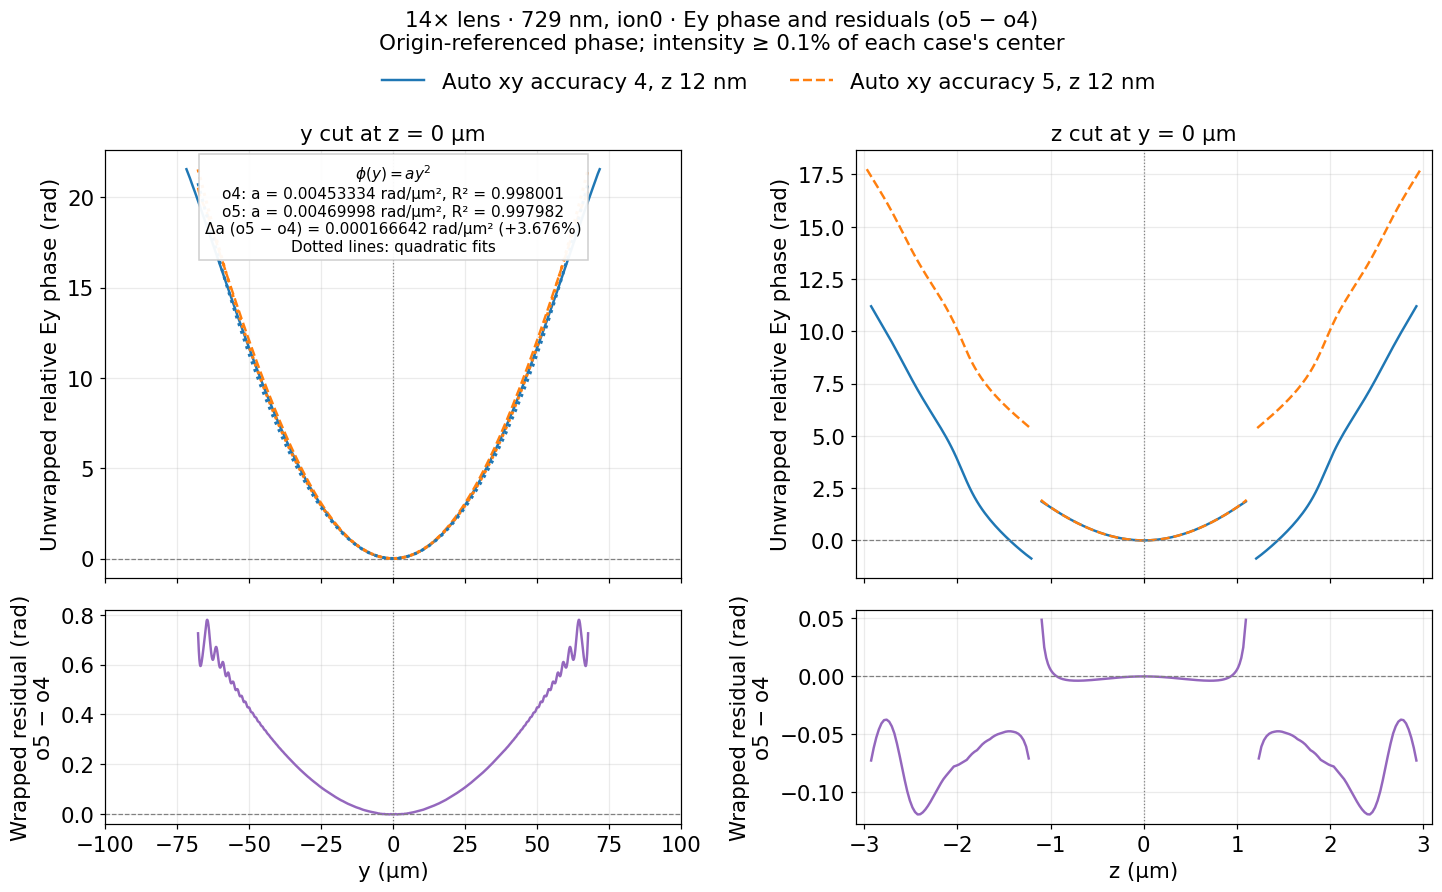

In [ ]:
# Compare ion0 lens Ey phase: o4 vs o5, both with a 12 nm z mesh step.
# Residuals are o5 − o4 wrapped to [−π, π] to remove 2π branch ambiguity.
ion0_mesh_root = Path("/home/philip_jacobson/Desktop/Planar_lens_scale_14X/729nm_ion0")
PHASE_THRESHOLD_O4_O5 = 1e-3  # 0.1% of each case's central |Ey|².
phase_paths_o4_o5 = {
    "Auto xy accuracy 4, z 12 nm": ion0_mesh_root / "xy_lambda_o4_z_12nm/lens.mat",
    "Auto xy accuracy 5, z 12 nm": ion0_mesh_root / "xy_lambda_o5_z_12nm/lens.mat",
}
phase_cuts_o4_o5, phase_residuals_o4_o5, fig_phases_o4_o5 = plot_ey_phase_with_residuals(
    phase_paths_o4_o5, threshold=PHASE_THRESHOLD_O4_O5, y_limits_um=(-100, 100), fit_y=True,
)
